In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay, RocCurveDisplay, roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_wine, load_digits
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA

In [ ]:
wine = load_wine()
digits = load_digits()

In [ ]:
class CustomClassifier:

  def prepare_data(self, dataset, split, dataset_name):
    X = dataset.data
    y = dataset.target

    self.dataset_name = dataset_name
    self.split = split

    X_train_raw, X_test_raw, self.y_train, self.y_test = train_test_split(X, y, test_size=split, random_state=42)

    self.scaler = StandardScaler()
    self._X_train_scaled = self.scaler.fit_transform(X_train_raw)
    self._X_test_scaled = self.scaler.transform(X_test_raw)

  def _evaluate_classifier(self, classifier, X_train, X_test, y_train):
    classifier.fit(X_train, y_train)
    y_pred = classifier.predict(X_test)
    accuracy = accuracy_score(self.y_test, y_pred)
    return accuracy, y_pred, classifier

  def _display_results(self, y_test, y_pred, classifier, X_test, dataset_name, split, kernel_name=None, pca_applied=False):
    classifier_name = type(classifier).__name__
    if pca_applied:
        result_label = f"{classifier_name}_PCA"
        if kernel_name:
            result_label += f"_{kernel_name}"
        print(f"--- Best Results for {classifier_name} (with PCA, {'Kernel: ' + kernel_name if kernel_name else ''}, Split: {split}) ---")
    elif kernel_name:
        result_label = f"{classifier_name}_{kernel_name}"
        print(f"--- Best Results for {classifier_name} (Kernel: {kernel_name}, Split: {split}) ---")
    else:
        result_label = classifier_name
        print(f"--- Best Results for {classifier_name} (Split: {split}) ---")

    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='copper')
    plt.title(f'Confusion Matrix for {result_label} (Split={split})')
    plt.show()
    plt.close()

    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, zero_division=0))
    print('Accuracy: ', accuracy_score(y_test, y_pred), '\n')

    # ROC Curve
    plt.figure(figsize=(10, 6))
    if hasattr(classifier, "predict_proba"):
        y_score = classifier.predict_proba(X_test)
        plot_roc = True
    elif hasattr(classifier, "decision_function"):
        y_score = classifier.decision_function(X_test)
        plot_roc = True
    else:
        print(f"Classifier {classifier_name} does not have predict_proba or decision_function for ROC curve.")
        y_score = None
        plot_roc = False

    if plot_roc:
        if y_score.ndim == 1: # Binary classification, decision_function returns 1D array
            RocCurveDisplay.from_estimator(classifier, X_test, y_test, ax=plt.gca())
            plt.title(f'ROC Curve for {result_label} (Split={split})')
        else: # Multi-class classification (One-vs-Rest)
            n_classes = y_score.shape[1]
            for i in range(n_classes):
                fpr, tpr, _ = roc_curve(y_test, y_score[:, i], pos_label=i)
                roc_auc = auc(fpr, tpr)
                plt.plot(fpr, tpr, label=f'Class {i} (AUC = {roc_auc:.2f})')
            plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
            plt.title(f'ROC Curves (One-vs-Rest) for {result_label} (Split={split})')
            plt.xlabel('False Positive Rate')
            plt.ylabel('True Positive Rate')
            plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()
    plt.close()


    if hasattr(classifier, 'loss_curve_'):
      plt.figure(figsize=(10, 6))
      plt.plot(classifier.loss_curve_)
      plt.title(f'Loss Curve for {result_label} (Split={split})')
      plt.xlabel('Number of Iterations')
      plt.ylabel('Loss')
      plt.grid(True)
      plt.show()
      plt.close()

  def get_svc_results(self):
    X_train = self._X_train_scaled
    X_test = self._X_test_scaled
    y_train = self.y_train

    all_svc_kernel_results = []
    kernel_names = ['linear', 'poly', 'rbf', 'sigmoid']
    for kernel_name in kernel_names:
      classifier = SVC(kernel=kernel_name, random_state=42)
      accuracy, y_pred, fitted_classifier = self._evaluate_classifier(classifier, X_train, X_test, y_train)
      all_svc_kernel_results.append({
          'accuracy': accuracy,
          'y_test': self.y_test,
          'y_pred': y_pred,
          'classifier': fitted_classifier,
          'kernel_name': kernel_name,
          'X_test': X_test
      })
    return all_svc_kernel_results

  def get_mlp_results(self):
    X_train = self._X_train_scaled
    X_test = self._X_test_scaled
    y_train = self.y_train

    classifier = MLPClassifier(hidden_layer_sizes=(10, 10, 10), max_iter=1000, random_state=42)
    accuracy, y_pred, fitted_classifier = self._evaluate_classifier(classifier, X_train, X_test, y_train)
    return {
        'accuracy': accuracy,
        'y_test': self.y_test,
        'y_pred': y_pred,
        'classifier': fitted_classifier,
        'X_test': X_test
    }

  def get_random_forest_results(self):
    X_train = self._X_train_scaled
    X_test = self._X_test_scaled
    y_train = self.y_train

    classifier = RandomForestClassifier(n_estimators=20, random_state=42)
    accuracy, y_pred, fitted_classifier = self._evaluate_classifier(classifier, X_train, X_test, y_train)
    return {
        'accuracy': accuracy,
        'y_test': self.y_test,
        'y_pred': y_pred,
        'classifier': fitted_classifier,
        'X_test': X_test
    }

  def get_svc_results_pca(self, n_components=0.95):
    pca = PCA(n_components=n_components, random_state=42)
    X_train_pca = pca.fit_transform(self._X_train_scaled)
    X_test_pca = pca.transform(self._X_test_scaled)

    y_train = self.y_train

    all_svc_kernel_results = []
    kernel_names = ['linear', 'poly', 'rbf', 'sigmoid']
    for kernel_name in kernel_names:
      classifier = SVC(kernel=kernel_name, random_state=42)
      accuracy, y_pred, fitted_classifier = self._evaluate_classifier(classifier, X_train_pca, X_test_pca, y_train)
      all_svc_kernel_results.append({
          'accuracy': accuracy,
          'y_test': self.y_test,
          'y_pred': y_pred,
          'classifier': fitted_classifier,
          'kernel_name': kernel_name,
          'X_test': X_test_pca # Return PCA transformed X_test
      })
    return all_svc_kernel_results

  def get_mlp_results_pca(self, n_components=0.95):
    pca = PCA(n_components=n_components, random_state=42)
    X_train_pca = pca.fit_transform(self._X_train_scaled)
    X_test_pca = pca.transform(self._X_test_scaled)

    y_train = self.y_train

    classifier = MLPClassifier(hidden_layer_sizes=(10, 10, 10), max_iter=1000, random_state=42)
    accuracy, y_pred, fitted_classifier = self._evaluate_classifier(classifier, X_train_pca, X_test_pca, y_train)
    return {
        'accuracy': accuracy,
        'y_test': self.y_test,
        'y_pred': y_pred,
        'classifier': fitted_classifier,
        'X_test': X_test_pca # Return PCA transformed X_test
    }

  def get_random_forest_results_pca(self, n_components=0.95):
    pca = PCA(n_components=n_components, random_state=42)
    X_train_pca = pca.fit_transform(self._X_train_scaled)
    X_test_pca = pca.transform(self._X_test_scaled)

    y_train = self.y_train

    classifier = RandomForestClassifier(n_estimators=20, random_state=42)
    accuracy, y_pred, fitted_classifier = self._evaluate_classifier(classifier, X_train_pca, X_test_pca, y_train)
    return {
        'accuracy': accuracy,
        'y_test': self.y_test,
        'y_pred': y_pred,
        'classifier': fitted_classifier,
        'X_test': X_test_pca # Return PCA transformed X_test
    }

In [ ]:
c = CustomClassifier()
splits = [0.2, 0.3, 0.4, 0.5]


Best Results for Wine Dataset

--- Best Results for SVC (Kernel: rbf, Split: 0.2) ---


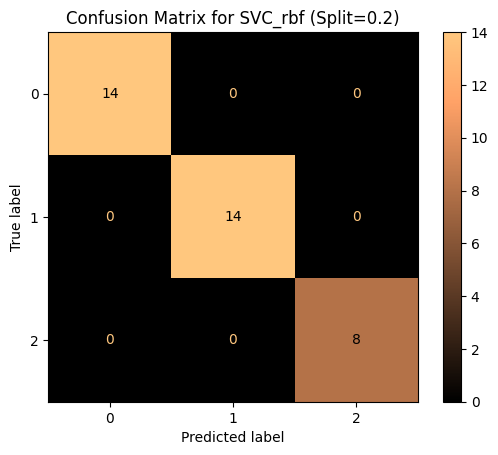

[[14  0  0]
 [ 0 14  0]
 [ 0  0  8]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00         8

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36

Accuracy:  1.0 



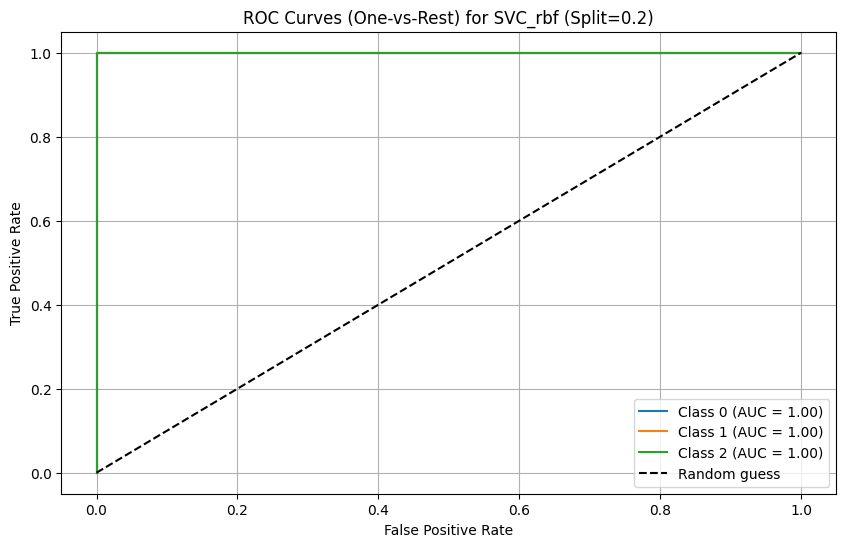

--- Best Results for MLPClassifier (Split: 0.2) ---


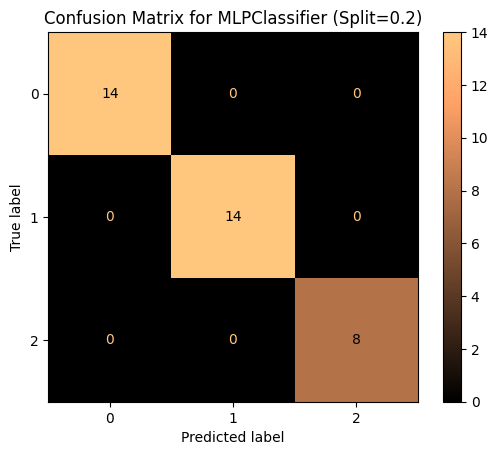

[[14  0  0]
 [ 0 14  0]
 [ 0  0  8]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00         8

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36

Accuracy:  1.0 



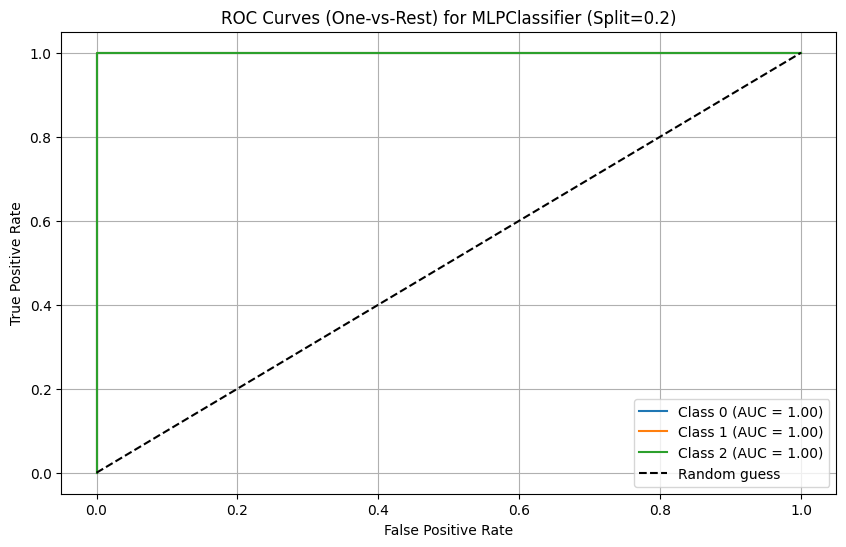

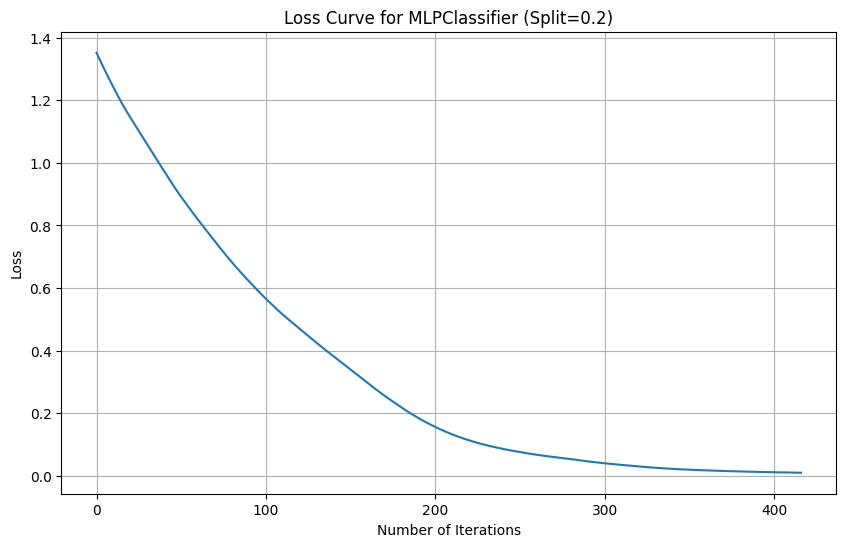

--- Best Results for RandomForestClassifier (Split: 0.2) ---


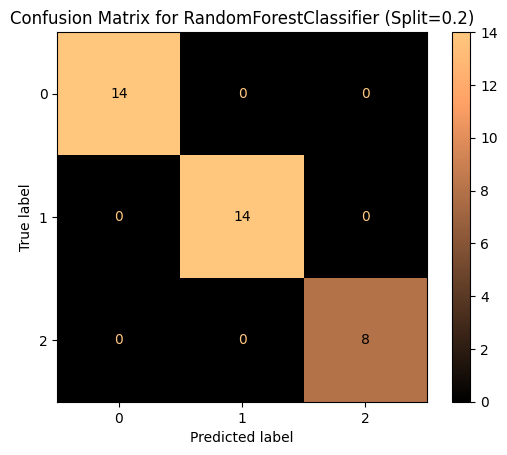

[[14  0  0]
 [ 0 14  0]
 [ 0  0  8]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00         8

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36

Accuracy:  1.0 



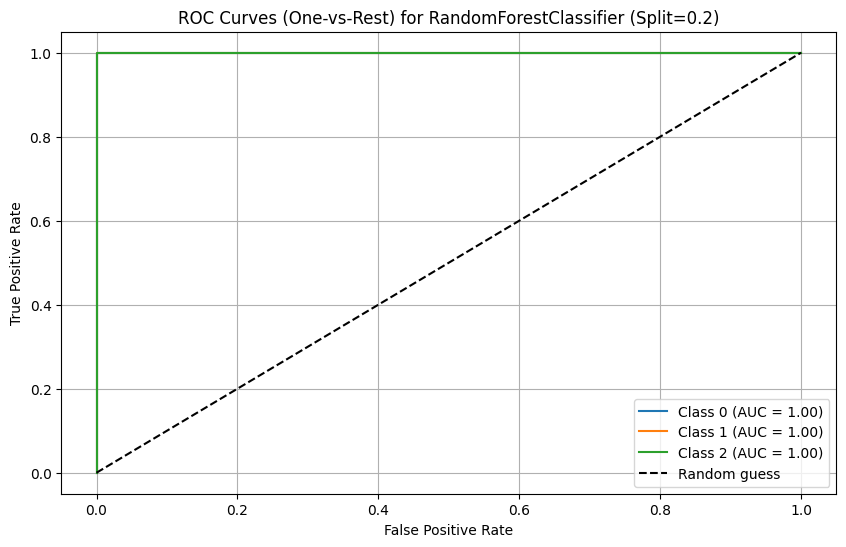

In [ ]:
# For Wine Dataset
best_svc_results_wine = {'accuracy': -1, 'split': None, 'kernel_name': None, 'X_test': None}
best_mlp_results_wine = {'accuracy': -1, 'split': None, 'X_test': None}
best_rf_results_wine = {'accuracy': -1, 'split': None, 'X_test': None}

for split in splits:
  c.prepare_data(wine, split, "wine")

  # SVC Results
  svc_kernel_results = c.get_svc_results()
  for res in svc_kernel_results:
      if res['accuracy'] > best_svc_results_wine['accuracy']:
          best_svc_results_wine = {
              'accuracy': res['accuracy'],
              'y_test': res['y_test'],
              'y_pred': res['y_pred'],
              'classifier': res['classifier'],
              'split': split,
              'kernel_name': res['kernel_name'],
              'X_test': res['X_test']
          }

  # MLP Results
  mlp_res = c.get_mlp_results()
  if mlp_res['accuracy'] > best_mlp_results_wine['accuracy']:
      best_mlp_results_wine = {
          'accuracy': mlp_res['accuracy'],
          'y_test': mlp_res['y_test'],
          'y_pred': mlp_res['y_pred'],
          'classifier': mlp_res['classifier'],
          'split': split,
          'X_test': mlp_res['X_test']
      }

  # Random Forest Results
  rf_res = c.get_random_forest_results()
  if rf_res['accuracy'] > best_rf_results_wine['accuracy']:
      best_rf_results_wine = {
          'accuracy': rf_res['accuracy'],
          'y_test': rf_res['y_test'],
          'y_pred': rf_res['y_pred'],
          'classifier': rf_res['classifier'],
          'split': split,
          'X_test': rf_res['X_test']
      }

# Display best results for Wine Dataset
print("\n========================================")
print("Best Results for Wine Dataset")
print("========================================\n")

if best_svc_results_wine['split'] is not None:
    c._display_results(best_svc_results_wine['y_test'], best_svc_results_wine['y_pred'],
                       best_svc_results_wine['classifier'], best_svc_results_wine['X_test'], "wine",
                       best_svc_results_wine['split'], best_svc_results_wine['kernel_name'])

if best_mlp_results_wine['split'] is not None:
    c._display_results(best_mlp_results_wine['y_test'], best_mlp_results_wine['y_pred'],
                       best_mlp_results_wine['classifier'], best_mlp_results_wine['X_test'], "wine",
                       best_mlp_results_wine['split'])

if best_rf_results_wine['split'] is not None:
    c._display_results(best_rf_results_wine['y_test'], best_rf_results_wine['y_pred'],
                       best_rf_results_wine['classifier'], best_rf_results_wine['X_test'], "wine",
                       best_rf_results_wine['split'])


Best Results for Digits Dataset

--- Best Results for SVC (Kernel: rbf, Split: 0.2) ---


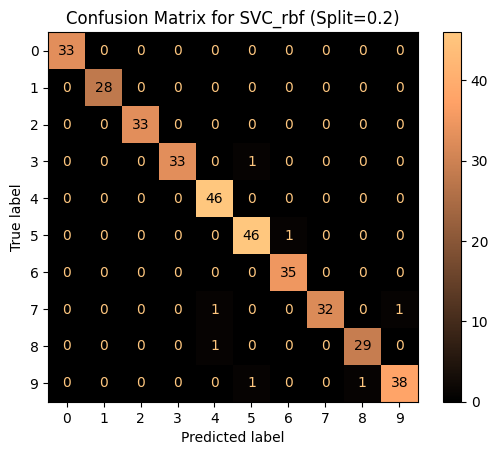

[[33  0  0  0  0  0  0  0  0  0]
 [ 0 28  0  0  0  0  0  0  0  0]
 [ 0  0 33  0  0  0  0  0  0  0]
 [ 0  0  0 33  0  1  0  0  0  0]
 [ 0  0  0  0 46  0  0  0  0  0]
 [ 0  0  0  0  0 46  1  0  0  0]
 [ 0  0  0  0  0  0 35  0  0  0]
 [ 0  0  0  0  1  0  0 32  0  1]
 [ 0  0  0  0  1  0  0  0 29  0]
 [ 0  0  0  0  0  1  0  0  1 38]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       1.00      1.00      1.00        28
           2       1.00      1.00      1.00        33
           3       1.00      0.97      0.99        34
           4       0.96      1.00      0.98        46
           5       0.96      0.98      0.97        47
           6       0.97      1.00      0.99        35
           7       1.00      0.94      0.97        34
           8       0.97      0.97      0.97        30
           9       0.97      0.95      0.96        40

    accuracy                           0.98       360
   macro avg       

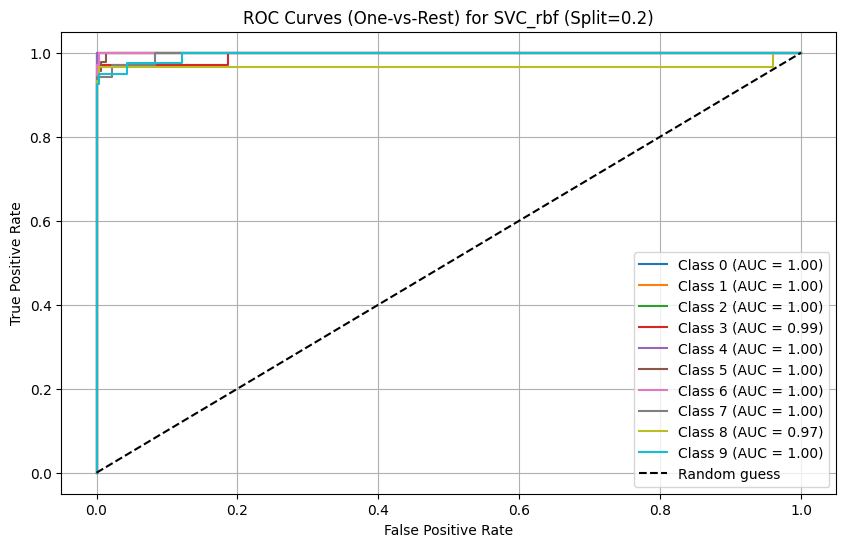

--- Best Results for MLPClassifier (Split: 0.4) ---


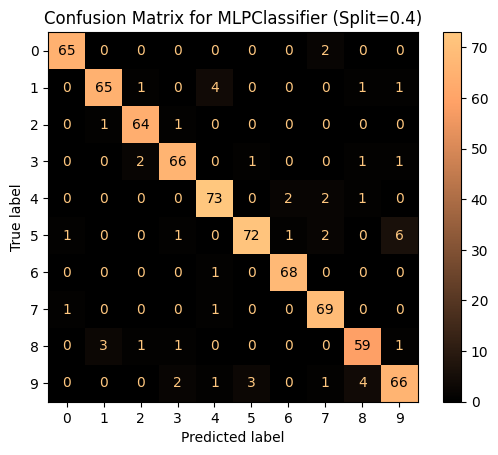

[[65  0  0  0  0  0  0  2  0  0]
 [ 0 65  1  0  4  0  0  0  1  1]
 [ 0  1 64  1  0  0  0  0  0  0]
 [ 0  0  2 66  0  1  0  0  1  1]
 [ 0  0  0  0 73  0  2  2  1  0]
 [ 1  0  0  1  0 72  1  2  0  6]
 [ 0  0  0  0  1  0 68  0  0  0]
 [ 1  0  0  0  1  0  0 69  0  0]
 [ 0  3  1  1  0  0  0  0 59  1]
 [ 0  0  0  2  1  3  0  1  4 66]]
              precision    recall  f1-score   support

           0       0.97      0.97      0.97        67
           1       0.94      0.90      0.92        72
           2       0.94      0.97      0.96        66
           3       0.93      0.93      0.93        71
           4       0.91      0.94      0.92        78
           5       0.95      0.87      0.91        83
           6       0.96      0.99      0.97        69
           7       0.91      0.97      0.94        71
           8       0.89      0.91      0.90        65
           9       0.88      0.86      0.87        77

    accuracy                           0.93       719
   macro avg       

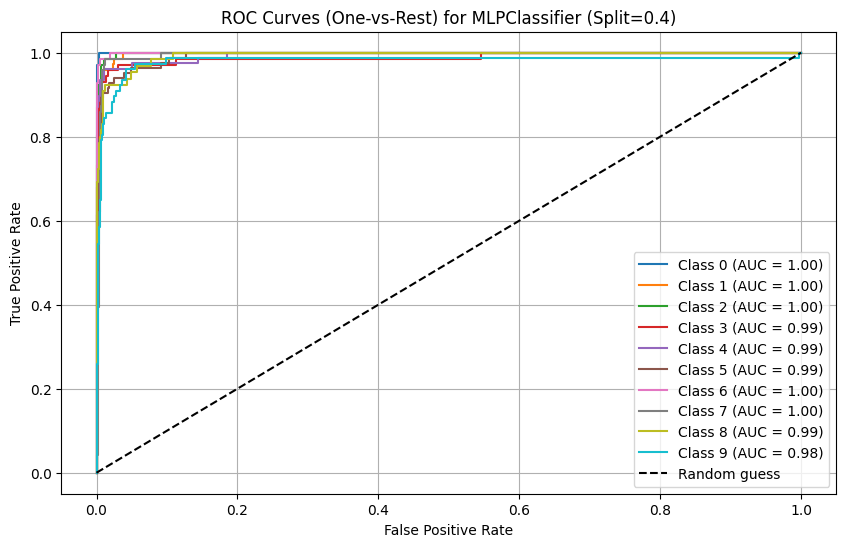

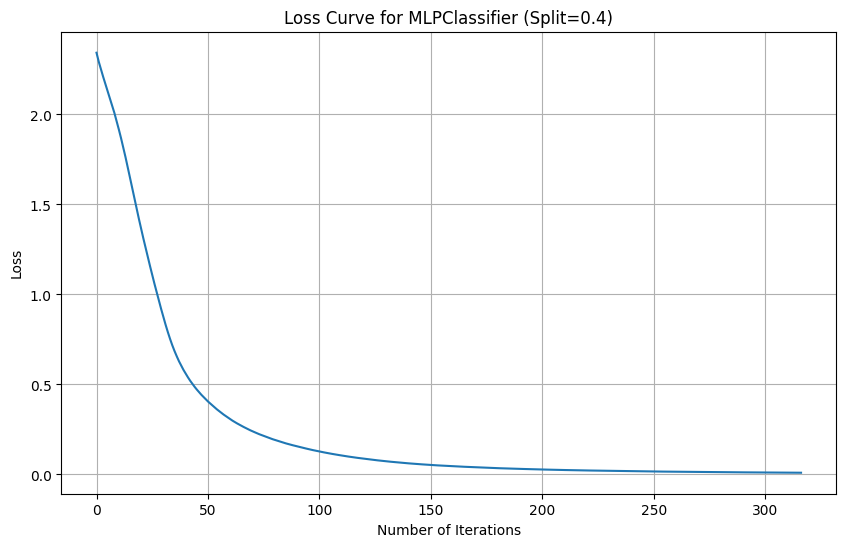

--- Best Results for RandomForestClassifier (Split: 0.4) ---


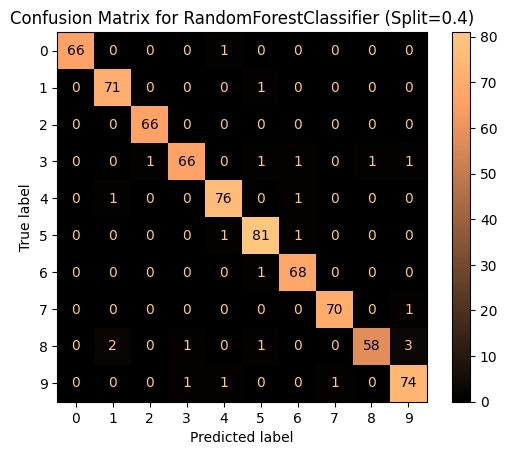

[[66  0  0  0  1  0  0  0  0  0]
 [ 0 71  0  0  0  1  0  0  0  0]
 [ 0  0 66  0  0  0  0  0  0  0]
 [ 0  0  1 66  0  1  1  0  1  1]
 [ 0  1  0  0 76  0  1  0  0  0]
 [ 0  0  0  0  1 81  1  0  0  0]
 [ 0  0  0  0  0  1 68  0  0  0]
 [ 0  0  0  0  0  0  0 70  0  1]
 [ 0  2  0  1  0  1  0  0 58  3]
 [ 0  0  0  1  1  0  0  1  0 74]]
              precision    recall  f1-score   support

           0       1.00      0.99      0.99        67
           1       0.96      0.99      0.97        72
           2       0.99      1.00      0.99        66
           3       0.97      0.93      0.95        71
           4       0.96      0.97      0.97        78
           5       0.95      0.98      0.96        83
           6       0.96      0.99      0.97        69
           7       0.99      0.99      0.99        71
           8       0.98      0.89      0.94        65
           9       0.94      0.96      0.95        77

    accuracy                           0.97       719
   macro avg       

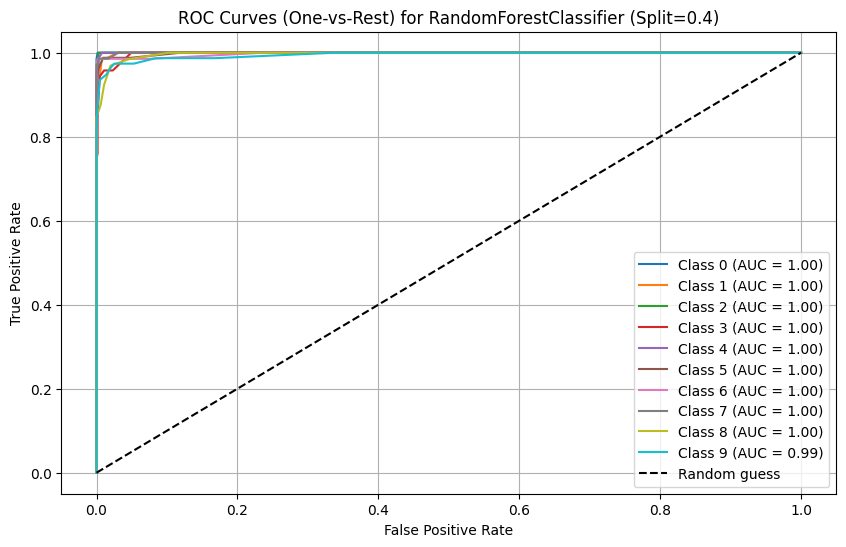

In [ ]:
# For Digits Dataset
best_svc_results_digits = {'accuracy': -1, 'split': None, 'kernel_name': None, 'X_test': None}
best_mlp_results_digits = {'accuracy': -1, 'split': None, 'X_test': None}
best_rf_results_digits = {'accuracy': -1, 'split': None, 'X_test': None}

for split in splits:
  c.prepare_data(digits, split, "digits")

  # SVC Results
  svc_kernel_results = c.get_svc_results()
  for res in svc_kernel_results:
      if res['accuracy'] > best_svc_results_digits['accuracy']:
          best_svc_results_digits = {
              'accuracy': res['accuracy'],
              'y_test': res['y_test'],
              'y_pred': res['y_pred'],
              'classifier': res['classifier'],
              'split': split,
              'kernel_name': res['kernel_name'],
              'X_test': res['X_test']
          }

  # MLP Results
  mlp_res = c.get_mlp_results()
  if mlp_res['accuracy'] > best_mlp_results_digits['accuracy']:
      best_mlp_results_digits = {
          'accuracy': mlp_res['accuracy'],
          'y_test': mlp_res['y_test'],
          'y_pred': mlp_res['y_pred'],
          'classifier': mlp_res['classifier'],
          'split': split,
          'X_test': mlp_res['X_test']
      }

  # Random Forest Results
  rf_res = c.get_random_forest_results()
  if rf_res['accuracy'] > best_rf_results_digits['accuracy']:
      best_rf_results_digits = {
          'accuracy': rf_res['accuracy'],
          'y_test': rf_res['y_test'],
          'y_pred': rf_res['y_pred'],
          'classifier': rf_res['classifier'],
          'split': split,
          'X_test': rf_res['X_test']
      }

# Display best results for Digits Dataset
print("\n========================================")
print("Best Results for Digits Dataset")
print("========================================\n")

if best_svc_results_digits['split'] is not None:
    c._display_results(best_svc_results_digits['y_test'], best_svc_results_digits['y_pred'],
                       best_svc_results_digits['classifier'], best_svc_results_digits['X_test'], "digits",
                       best_svc_results_digits['split'], best_svc_results_digits['kernel_name'])

if best_mlp_results_digits['split'] is not None:
    c._display_results(best_mlp_results_digits['y_test'], best_mlp_results_digits['y_pred'],
                       best_mlp_results_digits['classifier'], best_mlp_results_digits['X_test'], "digits",
                       best_mlp_results_digits['split'])

if best_rf_results_digits['split'] is not None:
    c._display_results(best_rf_results_digits['y_test'], best_rf_results_digits['y_pred'],
                       best_rf_results_digits['classifier'], best_rf_results_digits['X_test'], "digits",
                       best_rf_results_digits['split'])


Running Classifiers with PCA for Wine Dataset


Best Results for Wine Dataset (with PCA)

--- Best Results for SVC (with PCA, Kernel: linear, Split: 0.2) ---


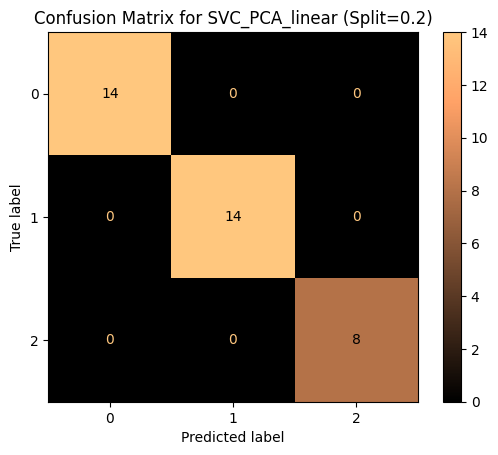

[[14  0  0]
 [ 0 14  0]
 [ 0  0  8]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00         8

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36

Accuracy:  1.0 



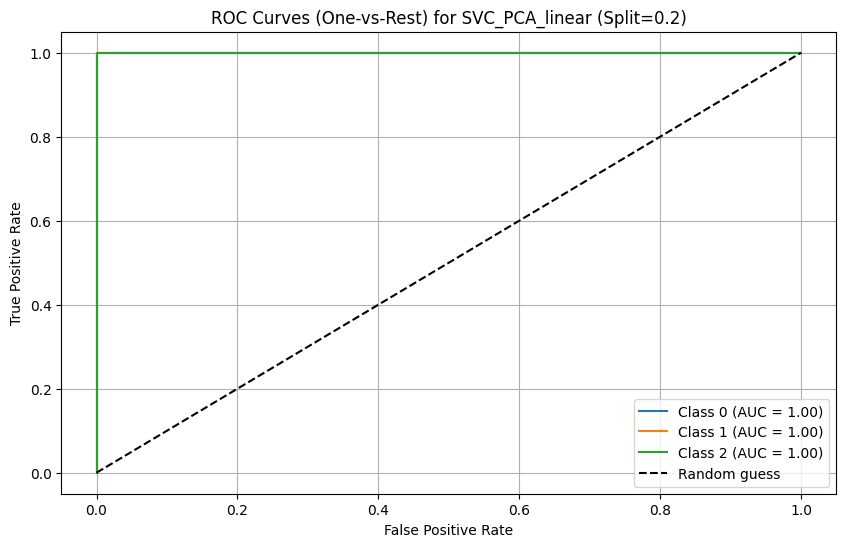

--- Best Results for MLPClassifier (with PCA, , Split: 0.5) ---


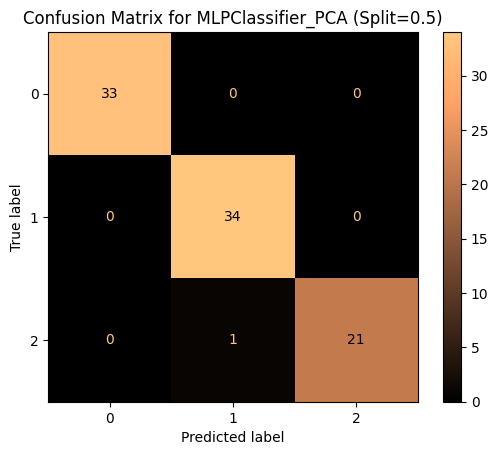

[[33  0  0]
 [ 0 34  0]
 [ 0  1 21]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       0.97      1.00      0.99        34
           2       1.00      0.95      0.98        22

    accuracy                           0.99        89
   macro avg       0.99      0.98      0.99        89
weighted avg       0.99      0.99      0.99        89

Accuracy:  0.9887640449438202 



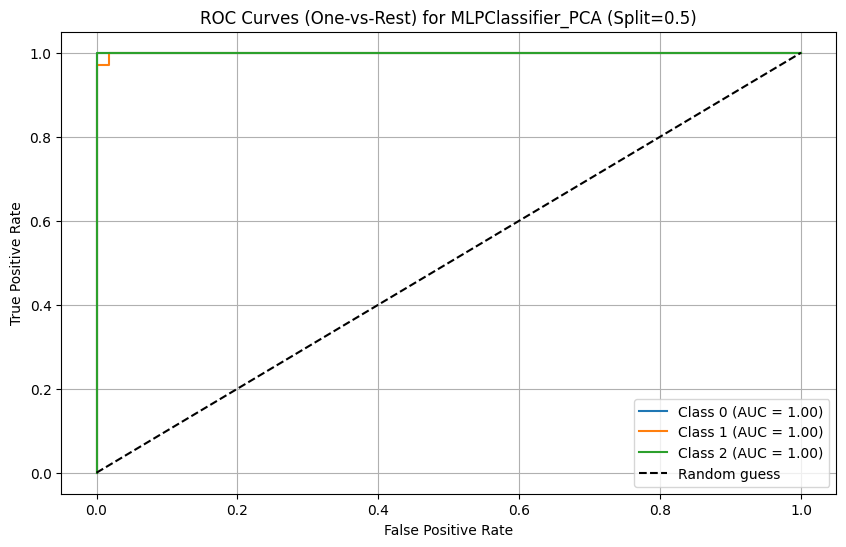

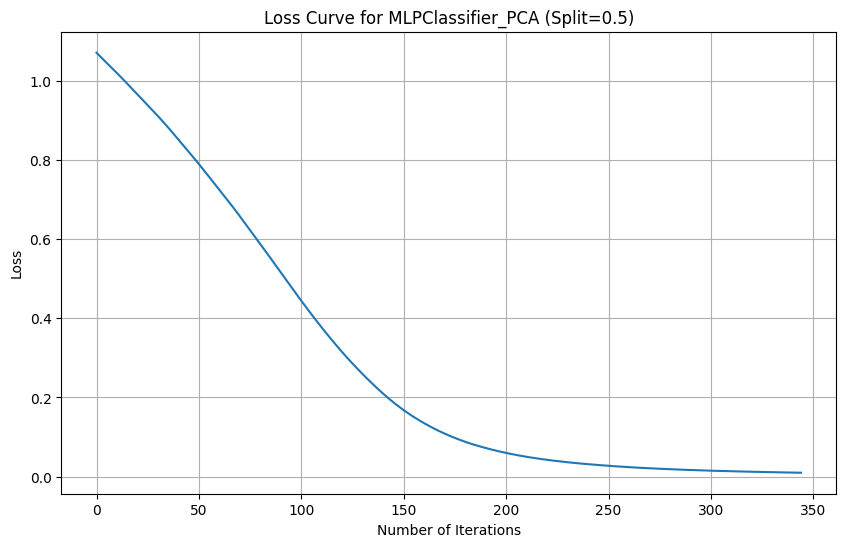

--- Best Results for RandomForestClassifier (with PCA, , Split: 0.2) ---


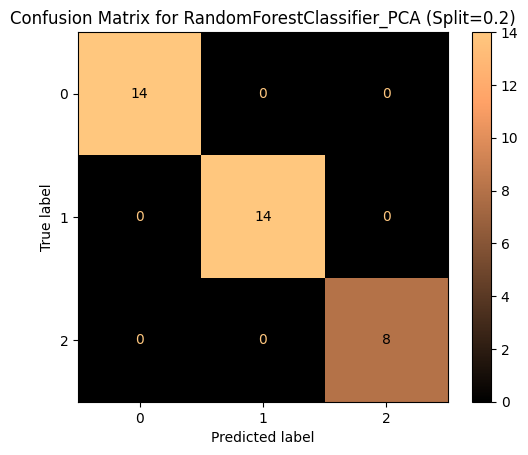

[[14  0  0]
 [ 0 14  0]
 [ 0  0  8]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00         8

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36

Accuracy:  1.0 



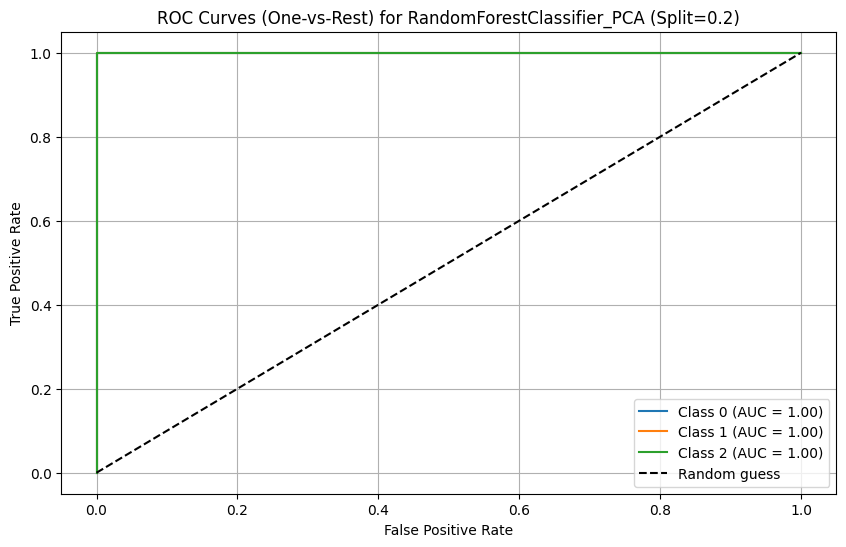

In [ ]:
# For Wine Dataset with PCA
best_svc_results_wine_pca = {'accuracy': -1, 'split': None, 'kernel_name': None, 'X_test': None}
best_mlp_results_wine_pca = {'accuracy': -1, 'split': None, 'X_test': None}
best_rf_results_wine_pca = {'accuracy': -1, 'split': None, 'X_test': None}

print("\n========================================")
print("Running Classifiers with PCA for Wine Dataset")
print("========================================\n")

for split in splits:
  c.prepare_data(wine, split, "wine")

  # SVC Results with PCA
  svc_kernel_results_pca = c.get_svc_results_pca()
  for res in svc_kernel_results_pca:
      if res['accuracy'] > best_svc_results_wine_pca['accuracy']:
          best_svc_results_wine_pca = {
              'accuracy': res['accuracy'],
              'y_test': res['y_test'],
              'y_pred': res['y_pred'],
              'classifier': res['classifier'],
              'split': split,
              'kernel_name': res['kernel_name'],
              'X_test': res['X_test']
          }

  # MLP Results with PCA
  mlp_res_pca = c.get_mlp_results_pca()
  if mlp_res_pca['accuracy'] > best_mlp_results_wine_pca['accuracy']:
      best_mlp_results_wine_pca = {
          'accuracy': mlp_res_pca['accuracy'],
          'y_test': mlp_res_pca['y_test'],
          'y_pred': mlp_res_pca['y_pred'],
          'classifier': mlp_res_pca['classifier'],
          'split': split,
          'X_test': mlp_res_pca['X_test']
      }

  # Random Forest Results with PCA
  rf_res_pca = c.get_random_forest_results_pca()
  if rf_res_pca['accuracy'] > best_rf_results_wine_pca['accuracy']:
      best_rf_results_wine_pca = {
          'accuracy': rf_res_pca['accuracy'],
          'y_test': rf_res_pca['y_test'],
          'y_pred': rf_res_pca['y_pred'],
          'classifier': rf_res_pca['classifier'],
          'split': split,
          'X_test': rf_res_pca['X_test']
      }

# Display best results for Wine Dataset with PCA
print("\n========================================")
print("Best Results for Wine Dataset (with PCA)")
print("========================================\n")

if best_svc_results_wine_pca['split'] is not None:
    c._display_results(best_svc_results_wine_pca['y_test'], best_svc_results_wine_pca['y_pred'],
                       best_svc_results_wine_pca['classifier'], best_svc_results_wine_pca['X_test'], "wine",
                       best_svc_results_wine_pca['split'], best_svc_results_wine_pca['kernel_name'], pca_applied=True)

if best_mlp_results_wine_pca['split'] is not None:
    c._display_results(best_mlp_results_wine_pca['y_test'], best_mlp_results_wine_pca['y_pred'],
                       best_mlp_results_wine_pca['classifier'], best_mlp_results_wine_pca['X_test'], "wine",
                       best_mlp_results_wine_pca['split'], pca_applied=True)

if best_rf_results_wine_pca['split'] is not None:
    c._display_results(best_rf_results_wine_pca['y_test'], best_rf_results_wine_pca['y_pred'],
                       best_rf_results_wine_pca['classifier'], best_rf_results_wine_pca['X_test'], "wine",
                       best_rf_results_wine_pca['split'], pca_applied=True)


Running Classifiers with PCA for Digits Dataset


Best Results for Digits Dataset (with PCA)

--- Best Results for SVC (with PCA, Kernel: rbf, Split: 0.2) ---


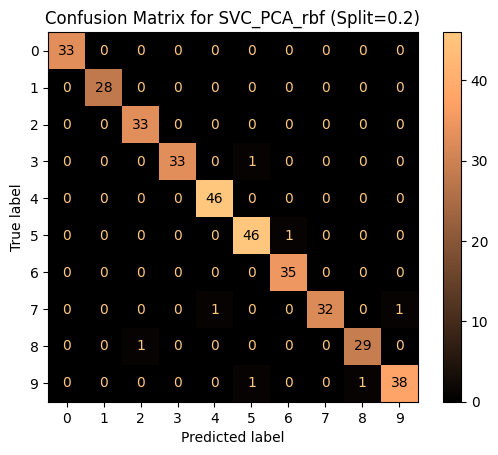

[[33  0  0  0  0  0  0  0  0  0]
 [ 0 28  0  0  0  0  0  0  0  0]
 [ 0  0 33  0  0  0  0  0  0  0]
 [ 0  0  0 33  0  1  0  0  0  0]
 [ 0  0  0  0 46  0  0  0  0  0]
 [ 0  0  0  0  0 46  1  0  0  0]
 [ 0  0  0  0  0  0 35  0  0  0]
 [ 0  0  0  0  1  0  0 32  0  1]
 [ 0  0  1  0  0  0  0  0 29  0]
 [ 0  0  0  0  0  1  0  0  1 38]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       1.00      1.00      1.00        28
           2       0.97      1.00      0.99        33
           3       1.00      0.97      0.99        34
           4       0.98      1.00      0.99        46
           5       0.96      0.98      0.97        47
           6       0.97      1.00      0.99        35
           7       1.00      0.94      0.97        34
           8       0.97      0.97      0.97        30
           9       0.97      0.95      0.96        40

    accuracy                           0.98       360
   macro avg       

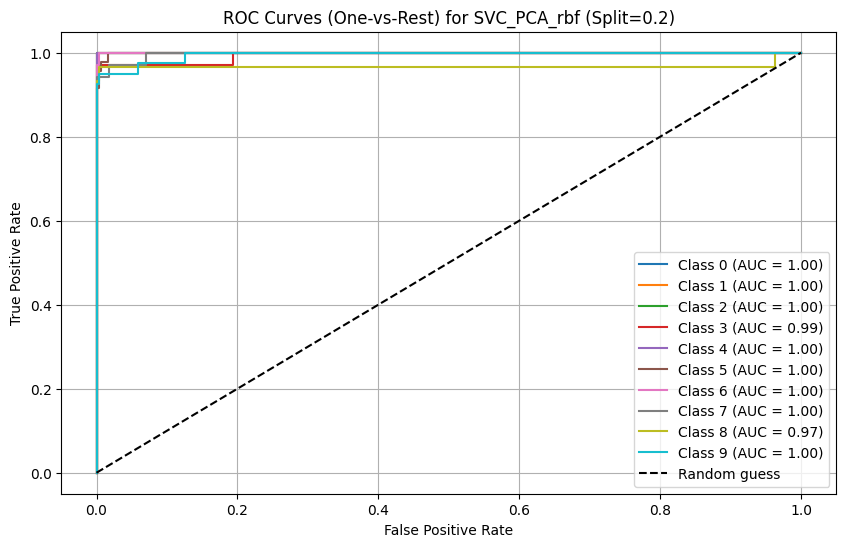

--- Best Results for MLPClassifier (with PCA, , Split: 0.2) ---


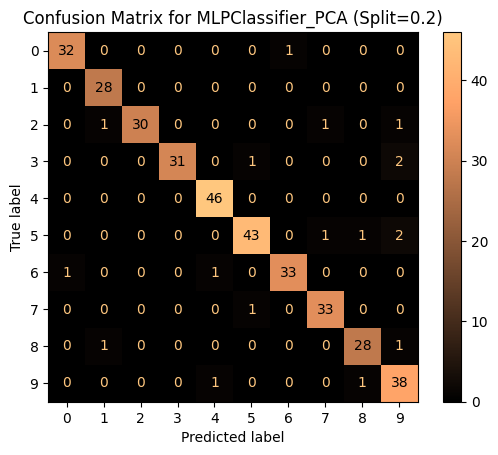

[[32  0  0  0  0  0  1  0  0  0]
 [ 0 28  0  0  0  0  0  0  0  0]
 [ 0  1 30  0  0  0  0  1  0  1]
 [ 0  0  0 31  0  1  0  0  0  2]
 [ 0  0  0  0 46  0  0  0  0  0]
 [ 0  0  0  0  0 43  0  1  1  2]
 [ 1  0  0  0  1  0 33  0  0  0]
 [ 0  0  0  0  0  1  0 33  0  0]
 [ 0  1  0  0  0  0  0  0 28  1]
 [ 0  0  0  0  1  0  0  0  1 38]]
              precision    recall  f1-score   support

           0       0.97      0.97      0.97        33
           1       0.93      1.00      0.97        28
           2       1.00      0.91      0.95        33
           3       1.00      0.91      0.95        34
           4       0.96      1.00      0.98        46
           5       0.96      0.91      0.93        47
           6       0.97      0.94      0.96        35
           7       0.94      0.97      0.96        34
           8       0.93      0.93      0.93        30
           9       0.86      0.95      0.90        40

    accuracy                           0.95       360
   macro avg       

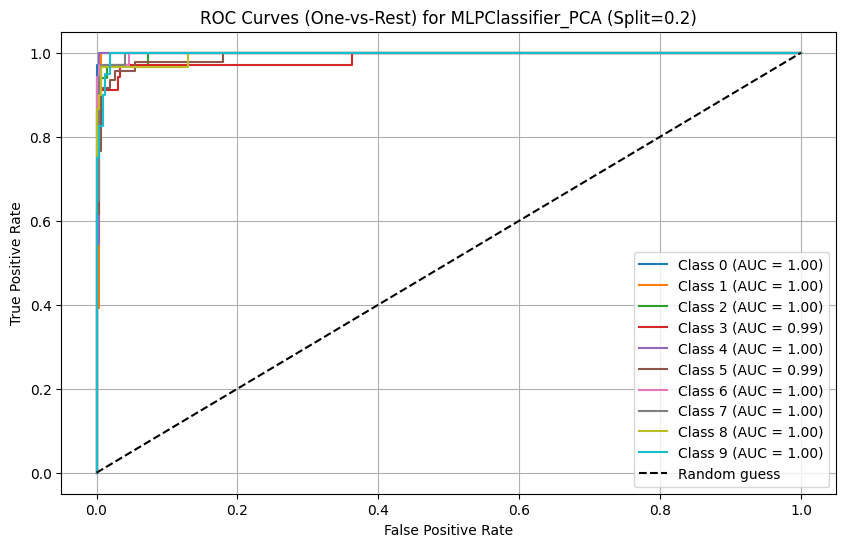

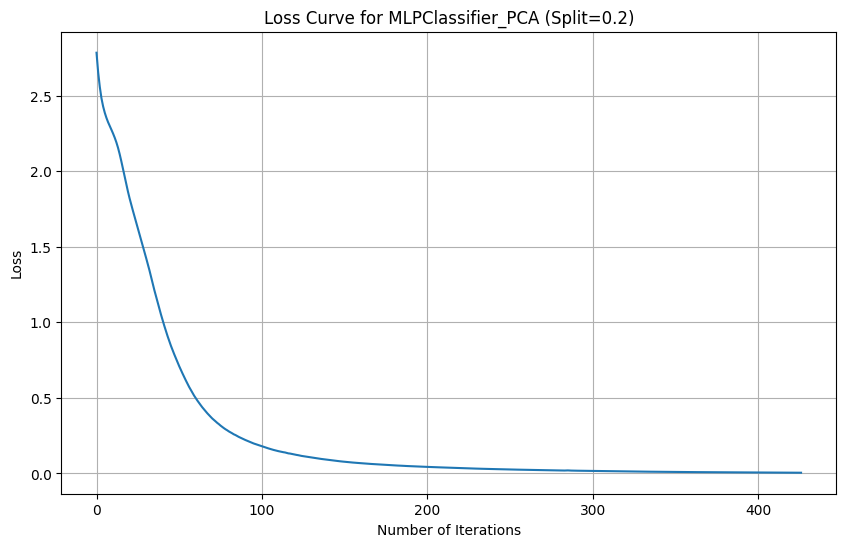

--- Best Results for RandomForestClassifier (with PCA, , Split: 0.2) ---


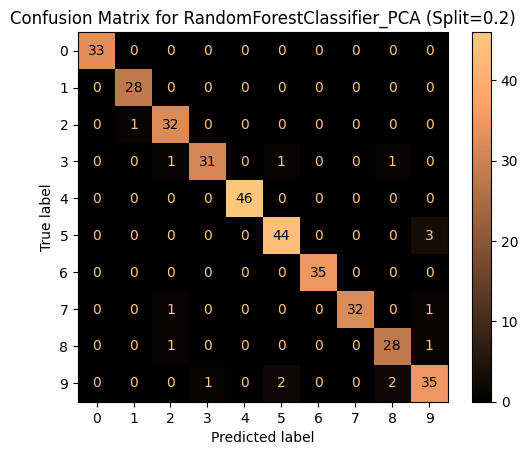

[[33  0  0  0  0  0  0  0  0  0]
 [ 0 28  0  0  0  0  0  0  0  0]
 [ 0  1 32  0  0  0  0  0  0  0]
 [ 0  0  1 31  0  1  0  0  1  0]
 [ 0  0  0  0 46  0  0  0  0  0]
 [ 0  0  0  0  0 44  0  0  0  3]
 [ 0  0  0  0  0  0 35  0  0  0]
 [ 0  0  1  0  0  0  0 32  0  1]
 [ 0  0  1  0  0  0  0  0 28  1]
 [ 0  0  0  1  0  2  0  0  2 35]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       0.97      1.00      0.98        28
           2       0.91      0.97      0.94        33
           3       0.97      0.91      0.94        34
           4       1.00      1.00      1.00        46
           5       0.94      0.94      0.94        47
           6       1.00      1.00      1.00        35
           7       1.00      0.94      0.97        34
           8       0.90      0.93      0.92        30
           9       0.88      0.88      0.88        40

    accuracy                           0.96       360
   macro avg       

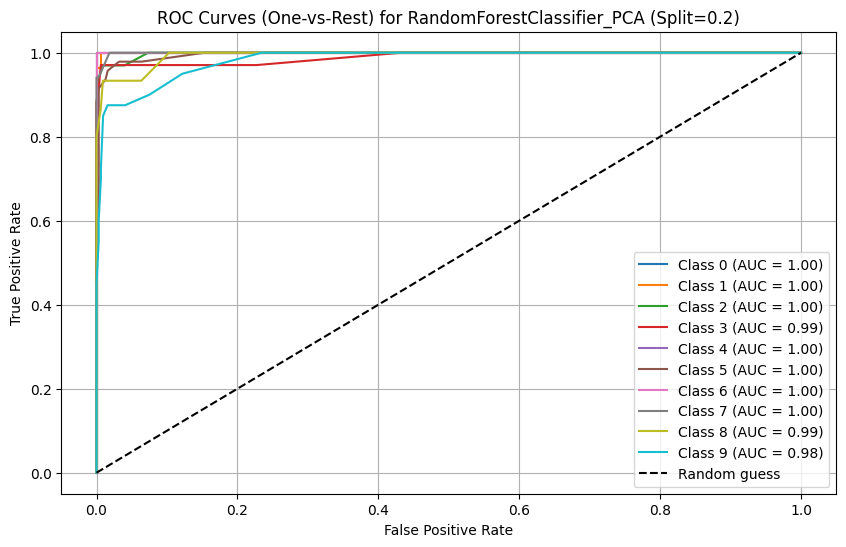

In [ ]:
# For Digits Dataset with PCA
best_svc_results_digits_pca = {'accuracy': -1, 'split': None, 'kernel_name': None, 'X_test': None}
best_mlp_results_digits_pca = {'accuracy': -1, 'split': None, 'X_test': None}
best_rf_results_digits_pca = {'accuracy': -1, 'split': None, 'X_test': None}

print("\n========================================")
print("Running Classifiers with PCA for Digits Dataset")
print("========================================\n")

for split in splits:
  c.prepare_data(digits, split, "digits")

  # SVC Results with PCA
  svc_kernel_results_pca = c.get_svc_results_pca()
  for res in svc_kernel_results_pca:
      if res['accuracy'] > best_svc_results_digits_pca['accuracy']:
          best_svc_results_digits_pca = {
              'accuracy': res['accuracy'],
              'y_test': res['y_test'],
              'y_pred': res['y_pred'],
              'classifier': res['classifier'],
              'split': split,
              'kernel_name': res['kernel_name'],
              'X_test': res['X_test']
          }

  # MLP Results with PCA
  mlp_res_pca = c.get_mlp_results_pca()
  if mlp_res_pca['accuracy'] > best_mlp_results_digits_pca['accuracy']:
      best_mlp_results_digits_pca = {
          'accuracy': mlp_res_pca['accuracy'],
          'y_test': mlp_res_pca['y_test'],
          'y_pred': mlp_res_pca['y_pred'],
          'classifier': mlp_res_pca['classifier'],
          'split': split,
          'X_test': mlp_res_pca['X_test']
      }

  # Random Forest Results with PCA
  rf_res_pca = c.get_random_forest_results_pca()
  if rf_res_pca['accuracy'] > best_rf_results_digits_pca['accuracy']:
      best_rf_results_digits_pca = {
          'accuracy': rf_res_pca['accuracy'],
          'y_test': rf_res_pca['y_test'],
          'y_pred': rf_res_pca['y_pred'],
          'classifier': rf_res_pca['classifier'],
          'split': split,
          'X_test': rf_res_pca['X_test']
      }

# Display best results for Digits Dataset with PCA
print("\n========================================")
print("Best Results for Digits Dataset (with PCA)")
print("========================================\n")

if best_svc_results_digits_pca['split'] is not None:
    c._display_results(best_svc_results_digits_pca['y_test'], best_svc_results_digits_pca['y_pred'],
                       best_svc_results_digits_pca['classifier'], best_svc_results_digits_pca['X_test'], "digits",
                       best_svc_results_digits_pca['split'], best_svc_results_digits_pca['kernel_name'], pca_applied=True)

if best_mlp_results_digits_pca['split'] is not None:
    c._display_results(best_mlp_results_digits_pca['y_test'], best_mlp_results_digits_pca['y_pred'],
                       best_mlp_results_digits_pca['classifier'], best_mlp_results_digits_pca['X_test'], "digits",
                       best_mlp_results_digits_pca['split'], pca_applied=True)

if best_rf_results_digits_pca['split'] is not None:
    c._display_results(best_rf_results_digits_pca['y_test'], best_rf_results_digits_pca['y_pred'],
                       best_rf_results_digits_pca['classifier'], best_rf_results_digits_pca['X_test'], "digits",
                       best_rf_results_digits_pca['split'], pca_applied=True)

## Classifier Comparison Table

In [ ]:
comparison_data = {
    'Classifier': [
        'SVC (Wine)', 'MLP (Wine)', 'Random Forest (Wine)',
        'SVC (Digits)', 'MLP (Digits)', 'Random Forest (Digits)',
        'SVC (Wine w/ PCA)', 'MLP (Wine w/ PCA)', 'Random Forest (Wine w/ PCA)',
        'SVC (Digits w/ PCA)', 'MLP (Digits w/ PCA)', 'Random Forest (Digits w/ PCA)'
    ],
    'Accuracy': [
        best_svc_results_wine['accuracy'], best_mlp_results_wine['accuracy'], best_rf_results_wine['accuracy'],
        best_svc_results_digits['accuracy'], best_mlp_results_digits['accuracy'], best_rf_results_digits['accuracy'],
        best_svc_results_wine_pca['accuracy'], best_mlp_results_wine_pca['accuracy'], best_rf_results_wine_pca['accuracy'],
        best_svc_results_digits_pca['accuracy'], best_mlp_results_digits_pca['accuracy'], best_rf_results_digits_pca['accuracy']
    ],
    'Best Split': [
        best_svc_results_wine['split'], best_mlp_results_wine['split'], best_rf_results_wine['split'],
        best_svc_results_digits['split'], best_mlp_results_digits['split'], best_rf_results_digits['split'],
        best_svc_results_wine_pca['split'], best_mlp_results_wine_pca['split'], best_rf_results_wine_pca['split'],
        best_svc_results_digits_pca['split'], best_mlp_results_digits_pca['split'], best_rf_results_digits_pca['split']
    ]
}

comparison_df = pd.DataFrame(comparison_data)
display(comparison_df.sort_values(by='Accuracy', ascending=False))

,Classifier,Accuracy,Best Split
0,SVC (Wine),1.000000,0.2
1,MLP (Wine),1.000000,0.2
2,Random Forest (Wine),1.000000,0.2
6,SVC (Wine w/ PCA),1.000000,0.2
8,Random Forest (Wine w/ PCA),1.000000,0.2
7,MLP (Wine w/ PCA),0.988764,0.5
3,SVC (Digits),0.980556,0.2
9,SVC (Digits w/ PCA),0.980556,0.2
5,Random Forest (Digits),0.968011,0.4
11,Random Forest (Digits w/ PCA),0.955556,0.2
